# Notebook 03 — Preprocessing

**Goal**: Transform raw data into a clean, scaled dataset ready for ML.

**What you'll learn:**
- Handling missing values (imputation)
- Why feature scaling matters for clustering
- StandardScaler vs MinMaxScaler
- sklearn Pipelines — preventing data leakage

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

sns.set_theme(style='whitegrid')

df = pd.read_csv('../data/customers_raw.csv')

# Re-add engineered columns
df['spending_ratio'] = (df['monthly_spending'] / (df['annual_income'] / 12)).round(4)
df['savings_ratio']  = (df['savings_balance'] / df['annual_income']).round(4)

print(f'Loaded {len(df)} customers')

Loaded 1000 customers


## Step 1 — Select ML features

We drop `customer_id` (not a feature) and `archetype` (the secret label — not for ML).

We keep all numeric features including our engineered ratios.

In [2]:
FEATURES = [
    'age',
    'annual_income',
    'monthly_spending',
    'savings_balance',
    'credit_score',
    'loan_amount',
    'num_existing_products',
    'months_as_customer',
    'spending_ratio',
    'savings_ratio',
]

X_raw = df[FEATURES].copy()
print('Feature matrix shape:', X_raw.shape)
print()
print('Missing values:')
print(X_raw.isnull().sum())

Feature matrix shape: (1000, 10)

Missing values:
age                       0
annual_income             0
monthly_spending          0
savings_balance          27
credit_score              0
loan_amount              23
num_existing_products     0
months_as_customer        0
spending_ratio            0
savings_ratio            27
dtype: int64


## Step 2 — Handle Missing Values (Imputation)

We have ~3% missing in `savings_balance` and `loan_amount`.

**Options:**
1. **Drop rows** — lose data, bad if many rows are missing
2. **Fill with mean** — simple, works for roughly normal distributions
3. **Fill with median** — better for skewed data (income, savings)
4. **Model-based imputation** — most accurate but complex

Since both columns are right-skewed, we use **median imputation**.

In [3]:
imputer = SimpleImputer(strategy='median')

X_imputed = pd.DataFrame(
    imputer.fit_transform(X_raw),
    columns=FEATURES
)

print('Missing values after imputation:')
print(X_imputed.isnull().sum())

print(f'\nMedian used for savings_balance: {imputer.statistics_[FEATURES.index("savings_balance")]:.2f}')
print(f'Median used for loan_amount:     {imputer.statistics_[FEATURES.index("loan_amount")]:.2f}')

Missing values after imputation:
age                      0
annual_income            0
monthly_spending         0
savings_balance          0
credit_score             0
loan_amount              0
num_existing_products    0
months_as_customer       0
spending_ratio           0
savings_ratio            0
dtype: int64

Median used for savings_balance: 5232.92
Median used for loan_amount:     9342.44


## Step 3 — Why Scaling is Critical for Clustering

KMeans clustering uses **distance** between points.
If `annual_income` ranges from 18,000 to 220,000 and `age` ranges from 18 to 65,
income will completely dominate the distance calculation — age barely matters.

**StandardScaler** transforms each feature to have:
- mean = 0
- standard deviation = 1

Formula: `z = (x - mean) / std`

After scaling, all features contribute equally to distance.

In [4]:
# Before scaling — look at the range differences
print('Feature ranges BEFORE scaling:')
print(X_imputed.agg(['min', 'max']).T.round(0))

Feature ranges BEFORE scaling:
                           min       max
age                       18.0      65.0
annual_income          15000.0  180667.0
monthly_spending         993.0    9425.0
savings_balance            0.0  158296.0
credit_score             426.0     850.0
loan_amount                0.0   54860.0
num_existing_products      1.0       6.0
months_as_customer         1.0     199.0
spending_ratio             0.0       2.0
savings_ratio              0.0       2.0


In [5]:
scaler = StandardScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(X_imputed),
    columns=FEATURES
)

print('Feature ranges AFTER scaling (all roughly -3 to +3):')
print(X_scaled.agg(['min', 'max']).T.round(2))

Feature ranges AFTER scaling (all roughly -3 to +3):
                        min   max
age                   -1.75  2.71
annual_income         -1.16  3.54
monthly_spending      -1.51  4.66
savings_balance       -0.80  3.68
credit_score          -2.63  1.89
loan_amount           -1.17  3.52
num_existing_products -1.13  2.41
months_as_customer    -1.48  3.97
spending_ratio        -1.79  4.74
savings_ratio         -1.01  4.00


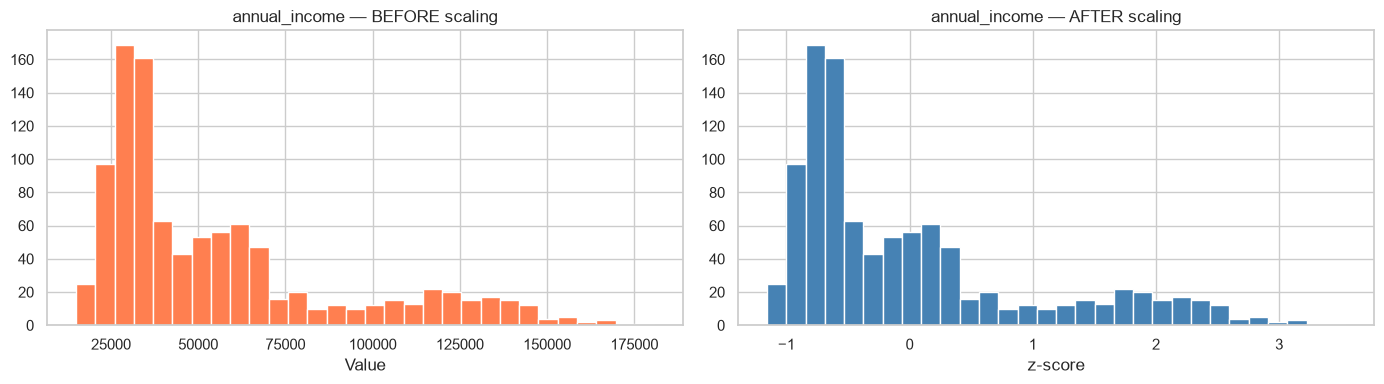

In [6]:
# Visualize the effect of scaling on two features
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(X_raw['annual_income'].dropna(), bins=30, color='coral', edgecolor='white')
axes[0].set_title('annual_income — BEFORE scaling')
axes[0].set_xlabel('Value')

axes[1].hist(X_scaled['annual_income'], bins=30, color='steelblue', edgecolor='white')
axes[1].set_title('annual_income — AFTER scaling')
axes[1].set_xlabel('z-score')

plt.tight_layout()
plt.show()

**Notice**: The *shape* of the distribution doesn't change — scaling only shifts the range. The underlying pattern is preserved.

## Step 4 — Building a sklearn Pipeline

A **Pipeline** chains preprocessing steps into a single object.
This is critical to prevent **data leakage** — a subtle but common ML bug.

**Data leakage** happens when information from test/validation data "leaks" into your model training.
Example: if you compute the global mean for imputation BEFORE splitting train/test,
the test data influenced the training process — your evaluation is misleading.

With a Pipeline, you `fit` only on training data and `transform` test data with those same parameters.

In [7]:
# Build the full preprocessing pipeline
preprocessing_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

# Fit and transform in one step
X_processed = preprocessing_pipeline.fit_transform(X_raw)
X_processed = pd.DataFrame(X_processed, columns=FEATURES)

print('Preprocessing pipeline applied.')
print(f'Output shape: {X_processed.shape}')
print(f'Mean of all features (should be ~0): {X_processed.mean().round(4).values}')

Preprocessing pipeline applied.
Output shape: (1000, 10)
Mean of all features (should be ~0): [-0. -0. -0. -0.  0. -0. -0. -0.  0. -0.]


## Step 5 — Save the processed data

In [8]:
import joblib
import os

os.makedirs('../data', exist_ok=True)

# Save processed features
X_processed.to_csv('../data/customers_processed.csv', index=False)

# Save the pipeline so we can apply it to new customers in production
joblib.dump(preprocessing_pipeline, '../data/preprocessing_pipeline.pkl')

print('Saved:')
print('  data/customers_processed.csv  — scaled feature matrix')
print('  data/preprocessing_pipeline.pkl — fitted pipeline (for production use)')

Saved:
  data/customers_processed.csv  — scaled feature matrix
  data/preprocessing_pipeline.pkl — fitted pipeline (for production use)


## Checkpoint — What you learned

| Concept | Why it matters |
|---|---|
| Median imputation | Handles skewed missing data better than mean |
| StandardScaler | Equalizes feature contributions in distance-based models |
| sklearn Pipeline | Prevents data leakage, clean production deployment |
| fit vs transform | `fit` learns parameters, `transform` applies them |

**Next up: Notebook 04 — PCA**
We have 10 features. PCA will reduce them to 2-3 dimensions so we can visualize clusters and remove redundancy.